# 1. PERSIAPAN
## 1.1 Cek GPU dan Instalasi Library

In [8]:
import os
import re
import random
import warnings
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from pathlib import Path
from collections import Counter
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import KFold
from sklearn.metrics import f1_score

# Cek ketersediaan Multilabel Stratified KFold
try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
    HAS_MULTILABEL_KFOLD = True
    print("MultilabelStratifiedKFold tersedia")
except ImportError:
    HAS_MULTILABEL_KFOLD = False
    print("iterstrat tidak tersedia, menggunakan KFold standar (Fallback aman)")

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

import torch
print(f"GPU tersedia: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Nama GPU: {torch.cuda.get_device_name(0)}")
    print(f"Jumlah GPU: {torch.cuda.device_count()}")

iterstrat tidak tersedia, menggunakan KFold standar (Fallback aman)
GPU tersedia: True
Nama GPU: Tesla T4
Jumlah GPU: 2


## 1.2 Membaca File Kaggle

In [9]:
input_dir = Path("/kaggle/input/competitions/action-2026-data-mining-competition/")
csv_files = {p.name: p for p in input_dir.rglob("*.csv")}
for name, p in csv_files.items():
    print(f"-{name} -> {p}")
    
train_df = pd.read_csv(input_dir / "train.csv")
test_df = pd.read_csv(input_dir / "test.csv")
submission_df = pd.read_csv(input_dir / "sample_submission.csv")
print("\nberhasil load file")
print(train_df.info())
print(test_df.info())

print("\n Terdapat 1554 baris kosong pada kolom judul_caption")

-sample_submission.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/sample_submission.csv
-train.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/train.csv
-test.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/test.csv

berhasil load file
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23297 entries, 0 to 23296
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   ID                       23297 non-null  int64 
 1   Teks                     23297 non-null  object
 2   Judul_Caption            21743 non-null  object
 3   Source                   23297 non-null  object
 4   Tanggal_Upload           23297 non-null  object
 5   Infrastruktur            23297 non-null  object
 6   Kesehatan                23297 non-null  object
 7   Administrasi_Perizinan   23297 non-null  object
 8   Lingkungan_Kebersihan    23297 non-null  object
 9   

# 2. PRA PEMROSESAN
## 2.1 Cek Keabsahan Kolom Target

In [10]:
pilar_cols = [
    'Infrastruktur', 'Kesehatan', 'Administrasi_Perizinan',
    'Lingkungan_Kebersihan', 'Ketertiban_Umum', 'Transportasi_LaluLintas',
    'Sosial_Bantuan', 'Keamanan_Kriminalitas', 'Pendidikan'
]


for i in pilar_cols:
    jumlah = train_df[i].value_counts()
    total_relevan = jumlah.get('Relevan', 0)
    total_tidak_relevan = jumlah.get('Tidak Relevan', 0)
    
    print(f"====={i}=====")
    print(f"Total relevan      : {total_relevan}")
    print(f"Total tidak relevan: {total_tidak_relevan}")
    print(f"Total keseluruhan  : {total_relevan+total_tidak_relevan}")

=====Infrastruktur=====
Total relevan      : 2803
Total tidak relevan: 20494
Total keseluruhan  : 23297
=====Kesehatan=====
Total relevan      : 2574
Total tidak relevan: 20723
Total keseluruhan  : 23297
=====Administrasi_Perizinan=====
Total relevan      : 1669
Total tidak relevan: 21628
Total keseluruhan  : 23297
=====Lingkungan_Kebersihan=====
Total relevan      : 1993
Total tidak relevan: 21304
Total keseluruhan  : 23297
=====Ketertiban_Umum=====
Total relevan      : 3191
Total tidak relevan: 20106
Total keseluruhan  : 23297
=====Transportasi_LaluLintas=====
Total relevan      : 2226
Total tidak relevan: 21071
Total keseluruhan  : 23297
=====Sosial_Bantuan=====
Total relevan      : 2885
Total tidak relevan: 20412
Total keseluruhan  : 23297
=====Keamanan_Kriminalitas=====
Total relevan      : 2718
Total tidak relevan: 20579
Total keseluruhan  : 23297
=====Pendidikan=====
Total relevan      : 2829
Total tidak relevan: 20468
Total keseluruhan  : 23297


## 2.2 Distribusi Kelas dan Antarkelas

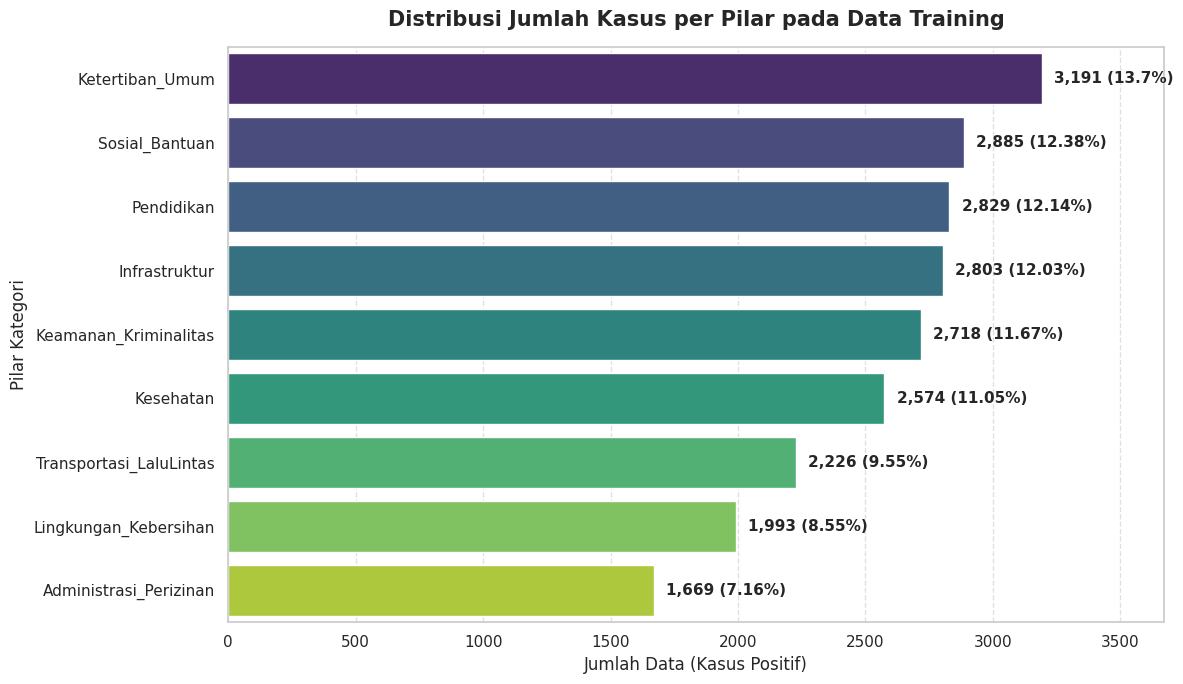


Distribusi Kasus Positif per Pilar:
                  Pilar  Jumlah_Kasus  Persentase
        Ketertiban_Umum          3191       13.70
         Sosial_Bantuan          2885       12.38
             Pendidikan          2829       12.14
          Infrastruktur          2803       12.03
  Keamanan_Kriminalitas          2718       11.67
              Kesehatan          2574       11.05
Transportasi_LaluLintas          2226        9.55
  Lingkungan_Kebersihan          1993        8.55
 Administrasi_Perizinan          1669        7.16

Total sampel training: 23,297

Analisis Class Imbalance:
  Label terbanyak  : Ketertiban_Umum (3,191)
  Label tersedikit : Administrasi_Perizinan (1,669)
  Imbalance Ratio  : 1.9x
  INFO: Distribusi relatif seimbang.


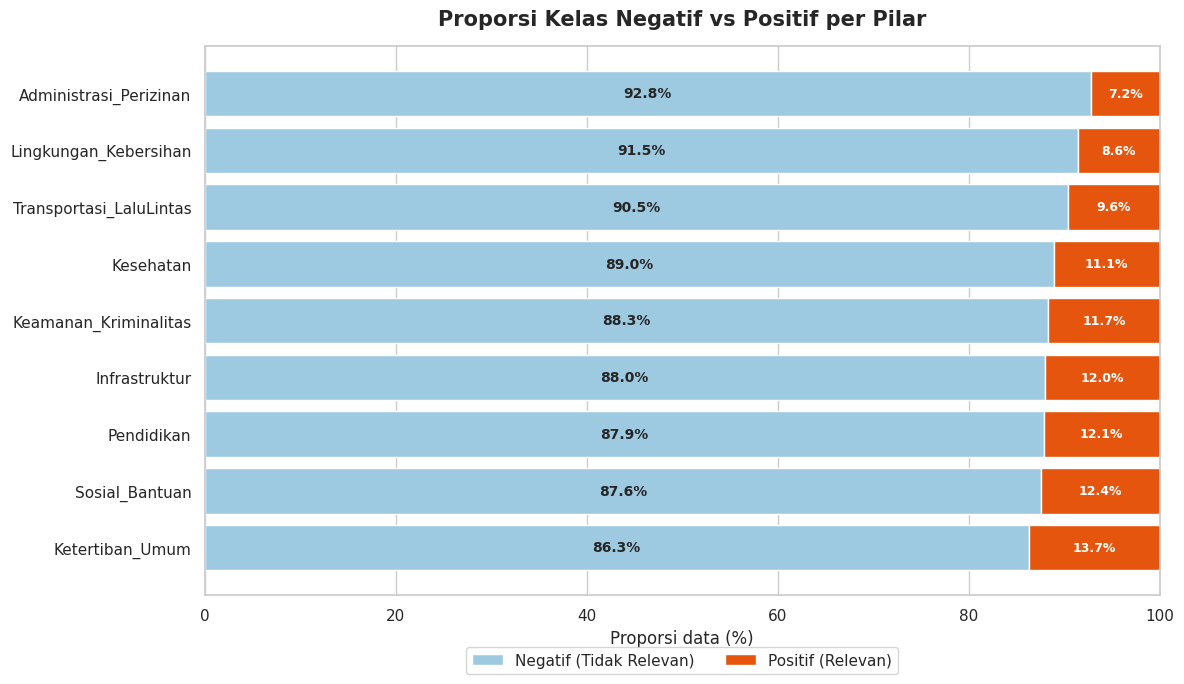


ANALISIS KETIMPANGAN TIAP PILAR (RASIO NEGATIF : POSITIF)
- Administrasi_Perizinan    Neg=21,628 | Pos=1,669 | Rasio = 12.96 : 1 | Positif  7.16% -> Moderat
- Lingkungan_Kebersihan     Neg=21,304 | Pos=1,993 | Rasio = 10.69 : 1 | Positif  8.55% -> Moderat
- Transportasi_LaluLintas   Neg=21,071 | Pos=2,226 | Rasio =  9.47 : 1 | Positif  9.55% -> Moderat
- Kesehatan                 Neg=20,723 | Pos=2,574 | Rasio =  8.05 : 1 | Positif 11.05% -> Moderat
- Keamanan_Kriminalitas     Neg=20,579 | Pos=2,718 | Rasio =  7.57 : 1 | Positif 11.67% -> Moderat
- Infrastruktur             Neg=20,494 | Pos=2,803 | Rasio =  7.31 : 1 | Positif 12.03% -> Moderat
- Pendidikan                Neg=20,468 | Pos=2,829 | Rasio =  7.24 : 1 | Positif 12.14% -> Moderat
- Sosial_Bantuan            Neg=20,412 | Pos=2,885 | Rasio =  7.08 : 1 | Positif 12.38% -> Moderat
- Ketertiban_Umum           Neg=20,106 | Pos=3,191 | Rasio =  6.30 : 1 | Positif 13.70% -> Moderat

Ringkasan:
  Pilar paling timpang : Administrasi_

In [11]:
# ============================================================
# HITUNG DISTRIBUSI KASUS POSITIF PER PILAR
# ============================================================
# Nilai yang dianggap "positif/relevan"
positive_values = ['relevan']

pilar_counts = {}
for col in pilar_cols:
    # Normalisasi: strip spasi, lowercase
    normalized = train_df[col].astype(str).str.strip().str.lower()
    # Hitung hanya yang termasuk kategori positif
    count = normalized.isin(positive_values).sum()
    pilar_counts[col] = count

# Buat Series dan urutkan dari yang terbanyak
counts_series = pd.Series(pilar_counts).sort_values(ascending=False)

# ============================================================
# VISUALISASI DISTRIBUSI
# ============================================================
total_samples = len(train_df)
percentage = (counts_series / total_samples * 100).round(2)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=counts_series.values,
    y=counts_series.index,
    hue=counts_series.index,
    palette='viridis',
    legend=False
)

plt.title('Distribusi Jumlah Kasus per Pilar pada Data Training',
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Jumlah Data (Kasus Positif)', fontsize=12)
plt.ylabel('Pilar Kategori', fontsize=12)

# Label angka + persentase di ujung bar
for i, (v, pct) in enumerate(zip(counts_series.values, percentage.values)):
    plt.text(
        v + (counts_series.max() * 0.015),
        i,
        f"{int(v):,} ({pct}%)",
        va='center', fontsize=11, fontweight='bold'
    )

plt.xlim(0, counts_series.max() * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# TABEL RINGKASAN DISTRIBUSI
dist_df = pd.DataFrame({
    'Pilar': counts_series.index,
    'Jumlah_Kasus': counts_series.values,
    'Persentase': percentage.values
})

print("\nDistribusi Kasus Positif per Pilar:")
print(dist_df.to_string(index=False))
print(f"\nTotal sampel training: {total_samples:,}")

max_cases = counts_series.max()
min_cases = counts_series.min()
imbalance_ratio = max_cases / min_cases if min_cases > 0 else float('inf')

print(f"\nAnalisis Class Imbalance:")
print(f"  Label terbanyak  : {counts_series.idxmax()} ({max_cases:,})")
print(f"  Label tersedikit : {counts_series.idxmin()} ({min_cases:,})")
print(f"  Imbalance Ratio  : {imbalance_ratio:.1f}x")

if imbalance_ratio > 5:
    print("  WARNING: Class imbalance signifikan! Perlu perhatian khusus pada label minoritas.")
elif imbalance_ratio > 2:
    print("  INFO: Ada class imbalance moderat.")
else:
    print("  INFO: Distribusi relatif seimbang.")

# ============================================================
# ANALISIS IMBALANCE DALAM TIAP PILAR (POSITIF vs NEGATIF)
# ============================================================
# Kategori berdasarkan proporsi kelas minoritas (positif), mengikuti rule of thumb
# yang umum dipakai (mis. panduan Google ML Crash Course):
#   >= 40%  -> Seimbang
#   20-40%  -> Ringan  (mild)
#   1-20%   -> Moderat (moderate)
#   < 1%    -> Ekstrem (extreme)
# Catatan: ini heuristik umum, bukan standar baku. Ganti sesuai literatur yang kamu pakai.
def kategori_imbalance(pct_pos):
    if pct_pos >= 40:
        return 'Seimbang'
    elif pct_pos >= 20:
        return 'Ringan'
    elif pct_pos >= 1:
        return 'Moderat'
    return 'Ekstrem'

rows = []
for col in pilar_cols:
    norm = train_df[col].astype(str).str.strip().str.lower()
    pos = int(norm.isin(positive_values).sum())
    neg = total_samples - pos
    pct_pos = pos / total_samples * 100
    rows.append({
        'Pilar': col,
        'Positif': pos,
        'Negatif': neg,
        '%Positif': round(pct_pos, 2),
        '%Negatif': round(100 - pct_pos, 2),
        'Rasio_Neg:Pos': round(neg / pos, 2) if pos > 0 else float('inf'),
        'Kategori': kategori_imbalance(pct_pos),
    })

imb_df = pd.DataFrame(rows).sort_values('Rasio_Neg:Pos', ascending=False).reset_index(drop=True)

# ---------- Diagram: proporsi negatif vs positif per pilar ----------
fig, ax = plt.subplots(figsize=(12, 7))
y_pos = np.arange(len(imb_df))

ax.barh(y_pos, imb_df['%Negatif'], color='#9ecae1', label='Negatif (Tidak Relevan)')
ax.barh(y_pos, imb_df['%Positif'], left=imb_df['%Negatif'], color='#e6550d', label='Positif (Relevan)')
ax.set_yticks(y_pos)
ax.set_yticklabels(imb_df['Pilar'])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Proporsi data (%)', fontsize=12)
ax.set_title('Proporsi Kelas Negatif vs Positif per Pilar', fontsize=15, fontweight='bold', pad=15)

for i, r in imb_df.iterrows():
    ax.text(r['%Negatif'] / 2, i, f"{r['%Negatif']:.1f}%", ha='center', va='center',
            fontsize=10, fontweight='bold')
    ax.text(r['%Negatif'] + r['%Positif'] / 2, i, f"{r['%Positif']:.1f}%", ha='center', va='center',
            fontsize=9, fontweight='bold', color='white')

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
plt.tight_layout()
plt.show()

# ---------- Analisis teks: rasio negatif dan positif ----------
print("\n" + "=" * 70)
print("ANALISIS KETIMPANGAN TIAP PILAR (RASIO NEGATIF : POSITIF)")
print("=" * 70)
for _, r in imb_df.iterrows():
    print(f"- {r['Pilar']:<25} Neg={r['Negatif']:>6,} | Pos={r['Positif']:>5,} | "
          f"Rasio = {r['Rasio_Neg:Pos']:>5.2f} : 1 | Positif {r['%Positif']:>5.2f}% -> {r['Kategori']}")

print("\nRingkasan:")
print(f"  Pilar paling timpang : {imb_df.iloc[0]['Pilar']} ({imb_df.iloc[0]['Rasio_Neg:Pos']:.1f} : 1)")
print(f"  Pilar paling seimbang: {imb_df.iloc[-1]['Pilar']} ({imb_df.iloc[-1]['Rasio_Neg:Pos']:.1f} : 1)")
print(f"  Rata-rata rasio Neg:Pos seluruh pilar: {imb_df['Rasio_Neg:Pos'].mean():.1f} : 1")
print(f"  Sebaran kategori: {imb_df['Kategori'].value_counts().to_dict()}")

# Kesimpulan otomatis: dalam pilar dan antar pilar
print("\nKesimpulan:")
print(f"  [Dalam tiap pilar] Positif hanya {imb_df['%Positif'].min():.1f}%-{imb_df['%Positif'].max():.1f}% "
      f"dari data (rasio {imb_df['Rasio_Neg:Pos'].min():.1f}-{imb_df['Rasio_Neg:Pos'].max():.1f} : 1).")
print("   -> Model rawan menebak '0' terus; F1 kelas 1 akan jadi penentu skor.")
print("   -> Solusi: class weight / pos_weight per pilar, focal loss, dan threshold tuning per label.")
print(f"  [Antar pilar] Selisih frekuensi positif terbesar vs terkecil = {imbalance_ratio:.1f}x.")
print("   -> Pilar kecil bisa tertinggal pada loss gabungan; gunakan stratified split per label")
print("      agar tiap fold memuat cukup positif dari pilar terkecil.")

## 2.3 Handle Missing Values

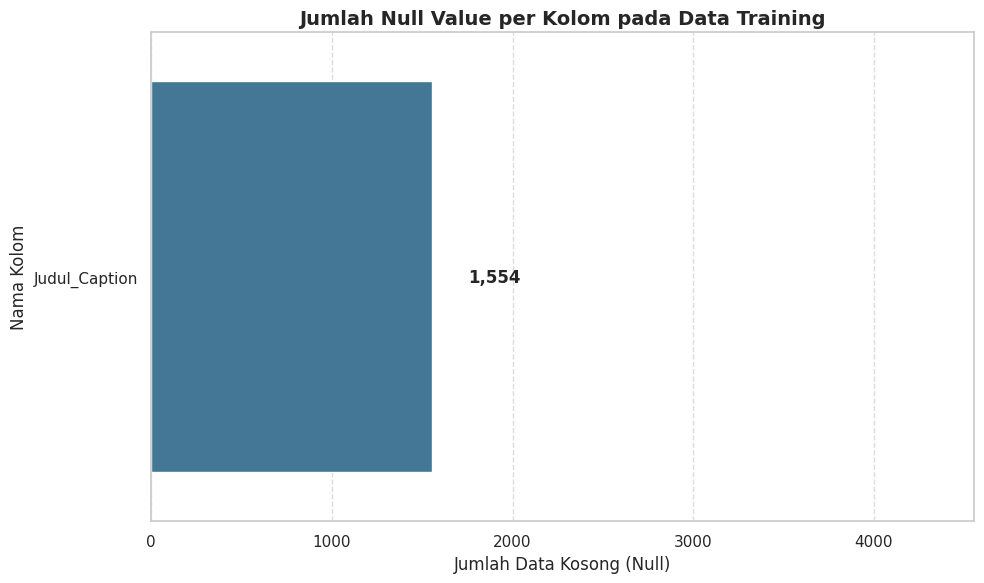

In [12]:
null_counts = train_df.isnull().sum()
null_counts = null_counts[null_counts > 0]

plt.figure(figsize=(10, 6))
sns.barplot(
    x=null_counts.values, 
    y=null_counts.index, 
    hue=null_counts.index,      
    palette='mako', 
    legend=False                
)

plt.title('Jumlah Null Value per Kolom pada Data Training', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Data Kosong (Null)', fontsize=12)
plt.ylabel('Nama Kolom', fontsize=12)

for i, v in enumerate(null_counts.values):
    plt.text(v + 200, i, f"{v:,}", va='center', fontsize=12, fontweight='bold')

plt.xlim(0, null_counts.max() + 3000)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [13]:
print("PREPROCESSING: HANDLE MISSING VALUES")

# Isi NaN dengan string kosong (bukan "nan") untuk mencegah artefak
for df in [train_df, test_df]:
    df['Judul_Caption'] = df['Judul_Caption'].fillna('')
    df['Teks'] = df['Teks'].fillna('')

print("Missing values diisi dengan string kosong\n")

train_df.info()

PREPROCESSING: HANDLE MISSING VALUES
Missing values diisi dengan string kosong

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23297 entries, 0 to 23296
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   ID                       23297 non-null  int64 
 1   Teks                     23297 non-null  object
 2   Judul_Caption            23297 non-null  object
 3   Source                   23297 non-null  object
 4   Tanggal_Upload           23297 non-null  object
 5   Infrastruktur            23297 non-null  object
 6   Kesehatan                23297 non-null  object
 7   Administrasi_Perizinan   23297 non-null  object
 8   Lingkungan_Kebersihan    23297 non-null  object
 9   Ketertiban_Umum          23297 non-null  object
 10  Transportasi_LaluLintas  23297 non-null  object
 11  Sosial_Bantuan           23297 non-null  object
 12  Keamanan_Kriminalitas    23297 non-null  object
 13  Pendidikan 

## 2.4 Noise pada Data

Menghitung 21 jenis noise pada 23,297 baris ...
Kandidat typo unik yang ditemukan: 1,446 kata

RINGKASAN PREVALENSI NOISE (persentase dari total baris)
                                  Noise  Jumlah_Baris  Persentase
                                  Emoji         14595       62.65
   Slang / kolokial (gak, banget, wkwk)          8107       34.80
      Singkatan informal (yg, dgn, tdk)          7183       30.83
               Elongasi huruf (paraaah)          3602       15.46
                     Leetspeak (p4rk1r)          3600       15.45
   Zero-width / karakter tak kasat mata          3036       13.03
   Pengulangan tanda baca (!!! ??? ...)          2806       12.04
          Fullwidth (huruf lebar penuh)          2068        8.88
 Homoglyph Cyrillic (huruf mirip Latin)          1894        8.13
Huruf dipisah titik/spasi (p.a.r.k.i.r)          1785        7.66
 Substitusi fonetik (aq, anak2, makasi)          1779        7.64
          Typo / salah ketik (estimasi)          1522   

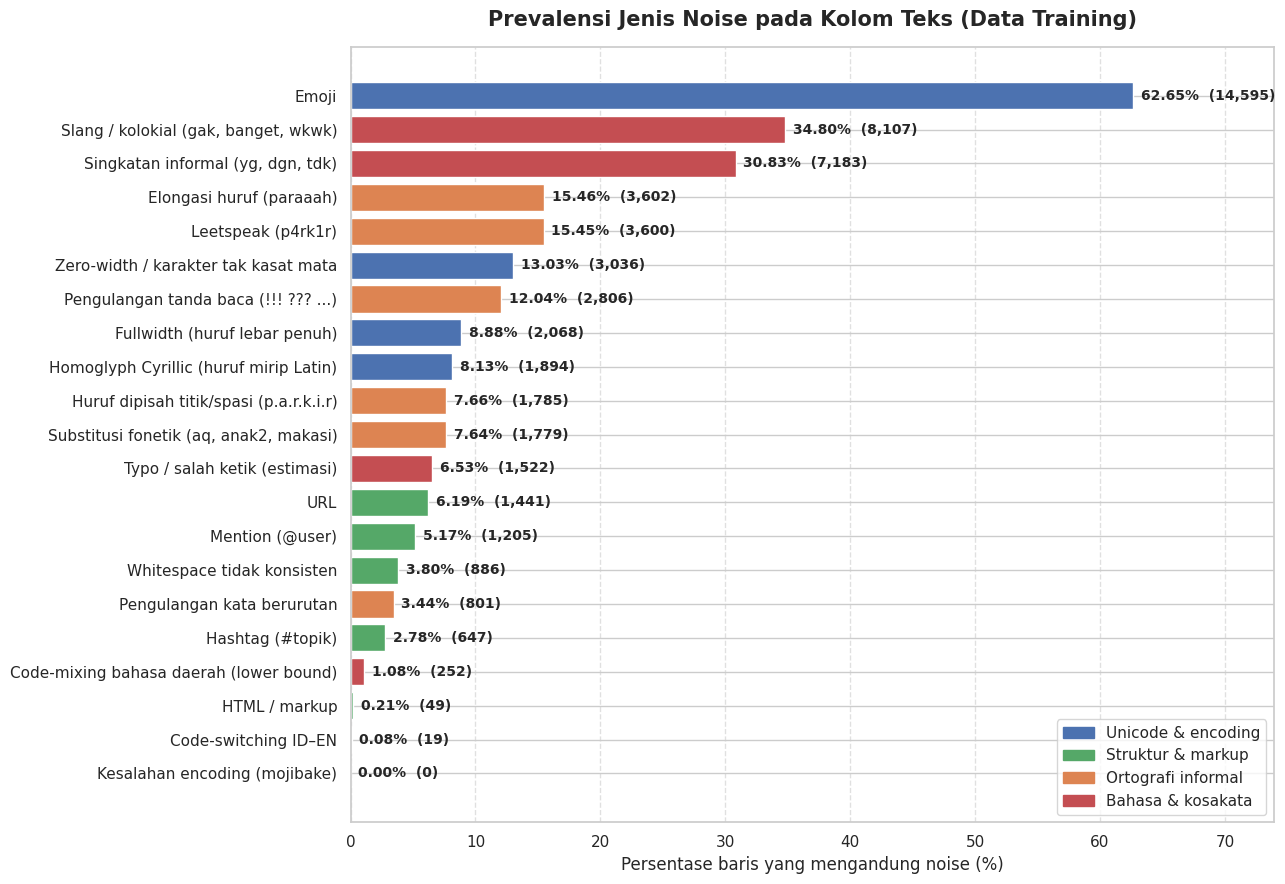


CONTOH BARIS UNTUK SETIAP JENIS NOISE

■ Zero-width / karakter tak kasat mata  [3,036 baris]
   • baris 5028 | bukti: ​, ‍
     teks: Tapi gimana yg tinggal di jawa barat tp k⟦ZWSP⟧t⟦ZWSP⟧p jakarta kmren minta rujukan buat ke rs yg di tuju gak bisa katanya 🥺 🤦⟦ZWJ⟧♂️
   • baris 1083 | bukti: ‍
     teks: Bagus lah b14r pda kappk. Klo itu bkan tmpat p.a.r.k.i.r 🤦⟦ZWJ⟧♂️

■ Fullwidth (huruf lebar penuh)  [2,068 baris]
   • baris 10070 | bukti: ｒｅｓａｈ
     teks: Tr0t04r bagus tp pejalan kaki ｒｅｓａｈ,, ribet dan kumuh,,,, , apxzezc yg раrkіr, рkl dan jukir liat sdh ga ada vewe ezwpclydt bg pejalan kaki..
   • baris 8775 | bukti: ｂｐｎｔ
     teks: Lelah qjqfm mfyn ini menunggu ｂｐｎｔ cair kapan kapan jhpyufh dong😮 🙄

■ Homoglyph Cyrillic (huruf mirip Latin)  [1,894 baris]
   • baris 8643 | bukti: р
     teks: Padahal bрjs jg bayar ga rcletd tp knp 0hybz semua ｄｉｐｅｒｓｕｌｉｔ astaga 😭
   • baris 5435 | bukti: е, а
     teks: Jakarta Selatan ada bеgаl dikejar sampai lobang semut 🛵

■ Kesalahan encoding 

In [25]:
raw = train_df['Teks'].fillna('').astype(str)
N = len(raw)

ZW_CHARS = '\u200b\u200c\u200d\ufeff\u2060\u00ad\u200e\u200f'
RE_ZW    = re.compile(f'[{ZW_CHARS}]')
RE_URL   = re.compile(r'https?://\S+|www\.\S+', re.I)
RE_MENT  = re.compile(r'@\w+')
RE_HASH  = re.compile(r'#\w+')

def base_text(s):
    """Versi 'netral' untuk detektor berbasis kata: NFKC, buang zero-width,
    lowercase, buang URL/mention/hashtag (agar token URL tidak dihitung sebagai noise lain)."""
    s = unicodedata.normalize('NFKC', s)
    s = RE_ZW.sub('', s).lower()
    s = RE_URL.sub(' ', s)
    s = RE_MENT.sub(' ', s)
    s = RE_HASH.sub(' ', s)
    return s

def tokenization(s):
    return re.findall(r"[a-z0-9]+", base_text(s))

base_tokens = [tokenization(s) for s in raw]          # cache token per baris

def vis(s, maxlen=170):
    """Tampilkan karakter tak kasat mata agar terlihat di contoh."""
    rep = {'\u200b':'⟦ZWSP⟧','\u200c':'⟦ZWNJ⟧','\u200d':'⟦ZWJ⟧','\ufeff':'⟦BOM⟧','\u2060':'⟦WJ⟧',
           '\u00ad':'⟦SHY⟧','\u200e':'⟦LRM⟧','\u200f':'⟦RLM⟧','\u00a0':'⟦NBSP⟧','\t':'⟦TAB⟧',
           '\n':'⟦NL⟧','\r':'⟦CR⟧'}
    for k, v in rep.items(): s = s.replace(k, v)
    return s if len(s) <= maxlen else s[:maxlen] + '…'

# ------------------------------------------------------------
# 1. LEKSIKON (daftar kata) — dibuat terpisah (tidak saling tumpang tindih)
# ------------------------------------------------------------
ABBR = set("""yg dgn dg utk untk tdk tdak krn krna jgn jd jdi sdh sdg blm blom sbg sbgai spt dlm dpt
tp tpi bgt bngt bs pd hrs kpd org orng tmn skrg skrng dll dsb dst dkk sm smua smpe bkn bnyk bnr brp
brpa byk emg hny jg kmrn krg lbh mrk msh sdkt sll stlh sblm tgl thn trs trims trmksh wkt gmn gmna
knp kpn dmn dmna""".split())

SLANG = set("""gue gw gua gwe lu lo loe elu gak ga nggak ngga nggk enggak engga ogah doang aja aj udah udh dah
sih deh dong nih tuh lah mah kok banget emang kayak kayaknya gimana kenapa ntar entar sampe cuma pake
bikin males ribet lemot kesel ngomong nyari pengen mending bener anjir anjay anjrit bjir woi woy cuy bro
sis gan sob ngab santuy mager baper bucin kepo receh cuan gabut gaje woles kuy mantul gercep kudu""".split())
SLANG -= ABBR
RE_LAUGH = re.compile(r'\b(?:wk){2,}\w*|\bw?k{3,}\b|\b(?:ha){2,}h?\b|\b(?:he){2,}h?\b|\b(?:hi){2,}\b|\bkwkw+\b')

PHON = set("aq kq aqu akuh plis pliss plisss gaes gais makasi makasih thx thanx tengkyu ciyus miapa".split())
Q_SAFE = {'qatar','iraq','tariq','qiblat','qadir','qolbu','quran','alquran'}

ENG = set("""the and you are was were this that with for not but just very can will have has had what why how when
where because please love good bad thank thanks sorry hello from they them their our your his her she its been
being more much some any would could should really also only still already never always people government
city road traffic hospital school free fix need want help work make take like""".split())
IND_FUNC = set("""yang dan di ke dari ini itu tidak gak ga nggak aja untuk dengan saya aku kita kami sudah udah
belum ada bisa juga atau karena kalau kalo sama mau lagi jadi pada oleh akan harus sih deh dong banget""".split())

REGIONAL = set("""ora wae wong iki kuwi kui kowe koe opo piye mung jare sampeyan gawe nuwun suwun tenan
teu euy atuh kumaha naon abdi hayang pisan kitu ieu eta geus keur kedah hoyong mangga nuhun punten
kagak ngape kemane ane ente gile indak nyo ndak""".split())

# ------------------------------------------------------------
# 2. DETEKTOR TYPO (berbasis korpus: kata langka yang berjarak 1 edit dari kata sangat sering)
# ------------------------------------------------------------
alpha_tokens = [[t for t in toks if t.isalpha()] for toks in base_tokens]
freq = Counter(t for toks in alpha_tokens for t in toks)
EXCL = ABBR | SLANG | PHON | ENG | IND_FUNC
FREQUENT = {w for w, c in freq.items() if c >= 50 and len(w) >= 4}
ALPHABET = 'abcdefghijklmnopqrstuvwxyz'

def edits1(w):
    sp = [(w[:i], w[i:]) for i in range(len(w) + 1)]
    dele = [a + b[1:] for a, b in sp if b]
    trans = [a + b[1] + b[0] + b[2:] for a, b in sp if len(b) > 1]
    repl = [a + c + b[1:] for a, b in sp if b for c in ALPHABET]
    ins = [a + c + b for a, b in sp for c in ALPHABET]
    return set(dele + trans + repl + ins)

typo_map = {}
for w, c in freq.items():
    if c > 2 or len(w) < 5 or len(w) > 14 or w in FREQUENT or w in EXCL:
        continue
    if re.search(r'(.)\1\1', w):          # elongasi bukan typo
        continue
    hits = [e for e in edits1(w) if e in FREQUENT and e[0] == w[0] and freq[e] >= 25 * c]
    if hits:
        typo_map[w] = max(hits, key=lambda e: freq[e])

# ------------------------------------------------------------
# 3. DETEKTOR PER JENIS NOISE  -> mengembalikan list bukti (kosong = tidak ada)
# ------------------------------------------------------------
def rx(pattern, flags=0, on='raw'):
    r = re.compile(pattern, flags)
    def f(i):
        s = raw.iat[i] if on == 'raw' else base_text(raw.iat[i])
        return [m.group(0) for m in r.finditer(s)]
    return f

def d_leet(i):
    """Token campuran huruf+angka, KECUALI angka hanya di awal (11malem, 5km) atau hanya di akhir (mp3, covid19)."""
    out = []
    for t in base_tokens[i]:
        if not (re.search(r'[a-z]', t) and re.search(r'\d', t)): continue
        if re.fullmatch(r'\d+[a-z]+', t) or re.fullmatch(r'[a-z]+\d+', t): continue
        out.append(t)
    return out

def d_abbr(i):  return [t for t in base_tokens[i] if t in ABBR]
def d_slang(i):
    out = [t for t in base_tokens[i] if t in SLANG]
    out += RE_LAUGH.findall(base_text(raw.iat[i]))
    return out
def d_phon(i):
    out = []
    for t in base_tokens[i]:
        if (t in PHON or re.fullmatch(r'[a-z]{3,}2', t) or re.fullmatch(r'(?:aku|kamu|iya|itu|ini|mau)h+', t)
                or (len(t) <= 3 and 'q' in t and t.isalpha() and t not in Q_SAFE)):
            out.append(t)
    return out
def d_typo(i):  return [f'{t}→{typo_map[t]}' for t in alpha_tokens[i] if t in typo_map]
def d_wordrep(i):
    return [m.group(0) for m in re.finditer(r'\b([a-z]{2,})(?:\s+\1\b)+', base_text(raw.iat[i]))]
def d_code(i):
    toks = base_tokens[i]
    eng = sorted({t for t in toks if t in ENG}); ind = {t for t in toks if t in IND_FUNC}
    return eng if (len(eng) >= 2 and len(ind) >= 2) else []
def d_regional(i):
    hits = sorted({t for t in base_tokens[i] if t in REGIONAL})
    return hits if len(hits) >= 2 else []
def d_spaced(i):
    t = unicodedata.normalize('NFKC', RE_ZW.sub('', raw.iat[i]))
    return [m.group(0) for m in re.finditer(r'\b(?:[A-Za-z][. ]){3,}[A-Za-z]\b', t)]
def d_space(i):
    s = raw.iat[i]; out = []
    if re.search(r'[ ]{2,}', s):                                  out.append('spasi ganda')
    if '\t' in s:                                                 out.append('tab')
    if re.search(r'[\r\n]', s):                                   out.append('baris baru')
    if re.search(r'[\u00a0\u2000-\u200a\u202f\u205f\u3000]', s):  out.append('spasi unicode non-standar')
    if s != s.strip():                                            out.append('spasi di tepi')
    return out

RE_EMOJI = r'[\U0001F000-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF\u203c\u2049\ufe0f]'
RE_MOJIBAKE = (r'\ufffd|[\x80-\x9f]|Ã[\u0080-\u00bf]|Â[\u00a0-\u00bf]|â€[™œ\u009d\u201c\u201d\u2122\u00a6]?|ðŸ[\u0080-\u00bf\u0152\u0153\u0161\u017e\u2018-\u203a]*')
RE_HTML = r'<\/?[a-zA-Z][^>]{0,80}>|&(?:amp|lt|gt|quot|apos|nbsp|#\d{2,5}|#x[0-9a-fA-F]{2,4});|\*\*[^*]+\*\*|\[[^\]]+\]\([^)]+\)'

NOISES = [
 # (nama, kelompok, detektor)
('Zero-width / karakter tak kasat mata',     'Unicode & encoding', rx(f'[{ZW_CHARS}]')),
('Fullwidth (huruf lebar penuh)',            'Unicode & encoding', rx(r'[\uff01-\uff5e]+')),
('Homoglyph Cyrillic (huruf mirip Latin)',   'Unicode & encoding', rx(r'[\u0400-\u04ff]+')),
('Kesalahan encoding (mojibake)',            'Unicode & encoding', rx(RE_MOJIBAKE)),
('Emoji',                                    'Unicode & encoding', rx(RE_EMOJI)),
('HTML / markup',                            'Struktur & markup',  rx(RE_HTML)),
('Whitespace tidak konsisten',               'Struktur & markup',  d_space),
('URL',                                      'Struktur & markup',  rx(r'https?://\S+|www\.\S+', re.I)),
('Mention (@user)',                          'Struktur & markup',  rx(r'@\w+')),
('Hashtag (#topik)',                         'Struktur & markup',  rx(r'#\w+')),
('Pengulangan tanda baca (!!! ??? ...)',     'Ortografi informal', rx(r'[!?]{2,}|([.,~])\1{2,}')),
('Elongasi huruf (paraaah)',                 'Ortografi informal', rx(r'([a-z])\1{2,}', 0, on='base')),
('Huruf dipisah titik/spasi (p.a.r.k.i.r)',  'Ortografi informal', d_spaced),
('Leetspeak (p4rk1r)',                       'Ortografi informal', d_leet),
('Substitusi fonetik (aq, anak2, makasi)',   'Ortografi informal', d_phon),
('Pengulangan kata berurutan',               'Ortografi informal', d_wordrep),
('Singkatan informal (yg, dgn, tdk)',        'Bahasa & kosakata',  d_abbr),
('Slang / kolokial (gak, banget, wkwk)',     'Bahasa & kosakata',  d_slang),
('Typo / salah ketik (estimasi)',            'Bahasa & kosakata',  d_typo),
('Code-switching ID–EN',                     'Bahasa & kosakata',  d_code),
('Code-mixing bahasa daerah (lower bound)',  'Bahasa & kosakata',  d_regional),
]

# ------------------------------------------------------------
# 4. HITUNG: jalankan tiap detektor di setiap baris
# ------------------------------------------------------------
print(f"Menghitung {len(NOISES)} jenis noise pada {N:,} baris ...")
rows, evid = [], {}
for name, grp, fn in NOISES:
    ev = [fn(i) for i in range(N)]
    evid[name] = ev
    n_hit = sum(1 for e in ev if len(e) > 0)
    rows.append({'Noise': name, 'Kelompok': grp, 'Jumlah_Baris': n_hit,
                 'Persentase': round(n_hit / N * 100, 2)})

noise_df = pd.DataFrame(rows).sort_values('Persentase', ascending=False).reset_index(drop=True)
print(f"Kandidat typo unik yang ditemukan: {len(typo_map):,} kata")
print("\nRINGKASAN PREVALENSI NOISE (persentase dari total baris)")
print(noise_df[['Noise', 'Jumlah_Baris', 'Persentase']].to_string(index=False))

# ------------------------------------------------------------
# 5. DIAGRAM BATANG
# ------------------------------------------------------------
warna = {'Unicode & encoding': '#4c72b0', 'Struktur & markup': '#55a868',
         'Ortografi informal': '#dd8452', 'Bahasa & kosakata': '#c44e52'}
plot_df = noise_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(13, 9))
ax.barh(plot_df['Noise'], plot_df['Persentase'], color=[warna[g] for g in plot_df['Kelompok']])
xmax = max(plot_df['Persentase'].max(), 1)
for y, (p, n) in enumerate(zip(plot_df['Persentase'], plot_df['Jumlah_Baris'])):
    ax.text(p + xmax * 0.01, y, f'{p:.2f}%  ({n:,})', va='center', fontsize=10, fontweight='bold')
ax.set_xlim(0, xmax * 1.18)
ax.set_xlabel('Persentase baris yang mengandung noise (%)', fontsize=12)
ax.set_title('Prevalensi Jenis Noise pada Kolom Teks (Data Training)', fontsize=15, fontweight='bold', pad=15)
ax.grid(axis='x', linestyle='--', alpha=0.6)
ax.legend(handles=[Patch(color=c, label=g) for g, c in warna.items()], loc='lower right')
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 6. CONTOH DATA (2 baris per noise)
# ------------------------------------------------------------
rng = random.Random(42)
print("\n" + "=" * 90 + "\nCONTOH BARIS UNTUK SETIAP JENIS NOISE\n" + "=" * 90)
for name, grp, fn in NOISES:
    ev = evid[name]
    hit_idx = [i for i, e in enumerate(ev) if e]
    short = [i for i in hit_idx if len(raw.iat[i]) <= 200]
    pool = short if len(short) >= 2 else hit_idx
    print(f"\n■ {name}  [{len(hit_idx):,} baris]")
    if not hit_idx:
        print("   (tidak ada baris terdeteksi — noise ini tidak ditemukan pada data)")
        continue
    for i in rng.sample(pool, min(2, len(pool))):
        bukti = ', '.join(dict.fromkeys(ev[i]))[:80]
        print(f"   • baris {train_df.index[i]} | bukti: {bukti}")
        print(f"     teks: {vis(raw.iat[i])}")

## 2.5 Membersihkan Kata

In [26]:
# BAGIAN 6: UNIVERSAL STRUCTURAL CLEANING (v2, tanpa leksikon kata)
import re, html, unicodedata

# --- 1. Karakter tak kasat mata (ditambah Hangul filler yang ditemukan di data) ---
INVISIBLE = ('\u200b\u200c\u200d\u200e\u200f\u2060\u2061\u2062\u2063\u00ad\ufeff'
             '\u115f\u1160\u3164\uffa0\u2800\ufe0e\ufe0f')
RE_INVIS = re.compile(f'[{INVISIBLE}]')

# --- 2. Homoglyph -> Latin (pemetaan karakter Unicode, BUKAN kamus kata) ---
# Dipetakan setelah lowercase. Hanya huruf yang benar-benar muncul/mirip Latin.
HOMOGLYPH = str.maketrans({
    'а':'a','в':'b','с':'c','е':'e','ё':'e','н':'h','һ':'h','і':'i','ї':'i','ј':'j',
    'к':'k','ӏ':'l','м':'m','о':'o','р':'p','ԛ':'q','ѕ':'s','т':'t','у':'y','х':'x',
    'ѵ':'v','ԁ':'d','ԝ':'w',
    'ο':'o','α':'a','ν':'v','ρ':'p','ι':'i','κ':'k','τ':'t',
})

RE_URL   = re.compile(r'https?://\S+|www\.\S+', re.I)
RE_MENT  = re.compile(r'@\w+')
RE_HASH  = re.compile(r'#(\w+)')
# huruf dipisah titik/spasi: "p.a.r.k.i.r", "m a h a s i s w a" (>=4 huruf tunggal)
RE_SPACED = re.compile(r'(?<![a-z0-9])(?:[a-z] ){3,}[a-z](?![a-z0-9])'      # spasi: >=4 huruf
                       r'|(?<![a-z0-9])(?:[a-z]\.){2,}[a-z](?![a-z0-9])')    # titik: >=3 huruf (k.t.p)
RE_TOKEN  = re.compile(r'[a-z0-9]+')
LEET = str.maketrans({'0':'o','1':'i','3':'e','4':'a','5':'s','7':'t'})
RE_ELONG = re.compile(r'([a-z])\1{2,}')
RE_PUNCT_REP = re.compile(r'([!?])\1+|[.,~]{2,}')
RE_EMOJI = re.compile(r'([\U0001F000-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF])')

def _despace(m):
    return re.sub(r'[ .]', '', m.group(0))

def _unleet(m):
    t = m.group(0)
    has_l, has_d = re.search(r'[a-z]', t), re.search(r'\d', t)
    if not (has_l and has_d): return t
    # angka hanya di awal (5km, 11malem) atau hanya di akhir (covid19, anak2): biarkan
    if re.fullmatch(r'\d+[a-z]+', t) or re.fullmatch(r'[a-z]+\d+', t): return t
    return t.translate(LEET)

def _elong(m):
    ch = m.group(1)
    return ch * (2 if ch in 'aiueo' else 1)   # vokal -> 2, konsonan -> 1

def structural_clean(text, *, homoglyph=True, despace=True, leet=True,
                     elong=True, punct=True, url_mention=True, emoji_sep=True):
    """Pembersihan struktural tanpa kamus kata. Tiap langkah bisa dimatikan (untuk ablation)."""
    if not isinstance(text, str):
        return ""
    text = html.unescape(text)                       # &amp; -> &
    text = unicodedata.normalize('NFKC', text)       # fullwidth -> ASCII
    text = RE_INVIS.sub('', text)                    # zero-width + hangul filler
    text = text.lower()
    if homoglyph:
        text = text.translate(HOMOGLYPH)             # Cyrillic/Greek -> Latin
    if url_mention:
        text = RE_URL.sub(' ', text)
        text = RE_MENT.sub(' ', text)
        text = RE_HASH.sub(r' \1 ', text)            # #infobdg -> infobdg
    if despace:
        text = RE_SPACED.sub(_despace, text)
    if leet:
        text = RE_TOKEN.sub(_unleet, text)
    if elong:
        text = RE_ELONG.sub(_elong, text)
    if punct:
        text = RE_PUNCT_REP.sub(lambda m: ' ' + (m.group(1) or '') + ' ', text)
    if emoji_sep:
        text = RE_EMOJI.sub(r' \1 ', text)           # emoji jadi token tersendiri
    return re.sub(r'\s+', ' ', text).strip()


# ------------------------------------------------------------
# ABLATION: ukur kontribusi tiap langkah dengan CV (macro-F1 rata-rata 9 label)
# ------------------------------------------------------------
def run_ablation(train_df, target_cols, y_train, n_splits=5, seed=42, sample=None):
    import numpy as np
    from scipy.sparse import hstack
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import f1_score
    from sklearn.model_selection import KFold

    steps = ['homoglyph', 'despace', 'leet', 'elong', 'punct', 'url_mention', 'emoji_sep']
    configs = {'baseline (NFKC+ZW saja)': {s: False for s in steps},
               'FULL v2': {s: True for s in steps}}
    for s in steps:                                   # leave-one-out
        configs[f'FULL tanpa {s}'] = {k: (k != s) for k in steps}

    idx = np.arange(len(train_df))
    if sample: idx = np.random.RandomState(seed).choice(idx, sample, replace=False)
    Y = np.asarray(y_train)[idx]
    folds = list(KFold(n_splits, shuffle=True, random_state=seed).split(idx))
    rows = []
    for name, cfg in configs.items():
        txt = (train_df['Judul_Caption'].fillna('').iloc[idx].map(lambda t: structural_clean(t, **cfg)) + ' [SEP] ' +
               train_df['Teks'].fillna('').iloc[idx].map(lambda t: structural_clean(t, **cfg))).values
        oof = np.zeros(Y.shape)
        for tr, va in folds:
            w = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
            c = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, sublinear_tf=True)
            Xtr = hstack([w.fit_transform(txt[tr]), c.fit_transform(txt[tr])]).tocsr()
            Xva = hstack([w.transform(txt[va]), c.transform(txt[va])]).tocsr()
            for j in range(Y.shape[1]):
                m = LogisticRegression(C=4, max_iter=300, class_weight='balanced').fit(Xtr, Y[tr, j])
                oof[va, j] = m.predict_proba(Xva)[:, 1]
        f1 = [f1_score(Y[:, j], oof[:, j] >= 0.5, average='macro') for j in range(Y.shape[1])]
        rows.append({'Konfigurasi': name, 'Macro-F1': np.mean(f1), **dict(zip(target_cols, f1))})
        print(f"{name:32s} {np.mean(f1):.4f}")
    import pandas as pd
    return pd.DataFrame(rows).sort_values('Macro-F1', ascending=False)

In [28]:
y_abl = np.stack(
    [(train_df[c].astype(str).str.strip().str.lower() == 'relevan').astype(int).values
     for c in pilar_cols], axis=1)
abl = run_ablation(train_df, pilar_cols, y_abl, n_splits=5)

# Hasil run pertama
# baseline (NFKC+ZW saja)          0.9246
# FULL v2                          0.9276
# FULL tanpa homoglyph             0.9258
# FULL tanpa despace               0.9266
# FULL tanpa leet                  0.9264
# FULL tanpa elong                 0.9274
# FULL tanpa punct                 0.9274
# FULL tanpa url_mention           0.9271
# FULL tanpa emoji_sep             0.9270

baseline (NFKC+ZW saja)          0.9246
FULL v2                          0.9276
FULL tanpa homoglyph             0.9258
FULL tanpa despace               0.9266
FULL tanpa leet                  0.9264
FULL tanpa elong                 0.9274
FULL tanpa punct                 0.9274
FULL tanpa url_mention           0.9271
FULL tanpa emoji_sep             0.9270


In [29]:
# BAGIAN 7 + 8 + 9 GABUNGAN:
# FEATURE EXTRACTION + NBSVM + OOF ENSEMBLE TRAINING
import numpy as np
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score


# 7.1 - DEFINISI KOLOM TARGET
target_cols = [
    'Infrastruktur', 'Kesehatan', 'Administrasi_Perizinan',
    'Lingkungan_Kebersihan', 'Ketertiban_Umum', 'Transportasi_LaluLintas',
    'Sosial_Bantuan', 'Keamanan_Kriminalitas', 'Pendidikan'
]


# 7.2 - VERIFIKASI train_df, test_df, dan final_text

if 'train_df' not in dir() or 'test_df' not in dir():
    raise NameError(
        "train_df atau test_df belum ada. "
        "Jalankan BAGIAN 2 (Load Data) terlebih dahulu."
    )

if 'final_text' not in train_df.columns or 'final_text' not in test_df.columns:
    raise ValueError(
        "Kolom 'final_text' belum ada. "
        "Jalankan BAGIAN 5 (Missing Values) dan BAGIAN 6 (Cleaning) terlebih dahulu."
    )

# ============================================================
# 7.3 - TF-IDF VECTORIZATION
# ============================================================
print("="*60)
print("FEATURE EXTRACTION: TF-IDF (WORD + CHAR N-GRAM)")
print("="*60)

# Word n-gram: menangkap frasa seperti "rumah sakit"
tfidf_word = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

# Char n-gram: menangkap typo/leetspeak (54mp4h ~ sampah)
tfidf_char = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

print("Fitting TF-IDF pada data train...")
X_word_train = tfidf_word.fit_transform(train_df['final_text'])
X_char_train = tfidf_char.fit_transform(train_df['final_text'])
X_train = hstack([X_word_train, X_char_train]).tocsr()

print("Transforming data test...")
X_word_test = tfidf_word.transform(test_df['final_text'])
X_char_test = tfidf_char.transform(test_df['final_text'])
X_test = hstack([X_word_test, X_char_test]).tocsr()

# PERBAIKAN: ENCODE TARGET DARI STRING KE INTEGER (0 dan 1)

# 1. Buat fungsi mapping yang aman
def encode_target(val):
    if pd.isna(val):
        return 0
    val_str = str(val).strip().lower()
    # Jika mengandung kata kunci positif, anggap 1, selain itu 0
    if val_str in ['relevan', '1', 'ya', 'true', 'yes']:
        return 1
    return 0

# 2. Terapkan fungsi ke semua kolom target di DataFrame
print("Mengonversi label 'Relevan'/'Tidak Relevan' menjadi 1/0...")
for col in target_cols:
    train_df[col] = train_df[col].apply(encode_target)

# 3. Sekarang AMAN untuk diubah menjadi numpy array bertipe integer
y_train = train_df[target_cols].astype(int).values

print(f"✓ Target shape: {y_train.shape}, dtype: {y_train.dtype}")
print(f"✓ Contoh 3 baris pertama y_train:\n{y_train[:3]}")

print(f"✓ Fitur train : {X_train.shape}")
print(f"✓ Fitur test  : {X_test.shape}")
print(f"✓ Target shape: {y_train.shape}, dtype: {y_train.dtype}")

# 8 - DEFINISI CLASS NBSVM

print("\n" + "="*60)
print("DEFINISI CLASS NBSVM")
print("="*60)

def get_nb_ratios(X, y_binary):
    """Hitung log-count ratio Naive Bayes untuk satu label biner"""
    p = X[y_binary == 1].sum(axis=0) + 1
    q = X[y_binary == 0].sum(axis=0) + 1
    r = np.log(p / p.sum()) - np.log(q / q.sum())
    return np.asarray(r).flatten()

class NBSVM:
    """NBSVM untuk multi-label: satu model per label"""
    def __init__(self, C=1.0):
        self.C = C
        self.models = []
        self.ratios = []
    
    def fit(self, X, Y):
        self.models = []
        self.ratios = []
        for i in range(Y.shape[1]):
            r = get_nb_ratios(X, Y[:, i])
            self.ratios.append(r)
            X_nb = X.multiply(csr_matrix(r))
            model = LogisticRegression(
                C=self.C, max_iter=1000,
                class_weight='balanced', solver='lbfgs'
            )
            model.fit(X_nb, Y[:, i])
            self.models.append(model)
        return self
    
    def predict_proba(self, X):
        probs = np.zeros((X.shape[0], len(self.models)))
        for i, (model, r) in enumerate(zip(self.models, self.ratios)):
            X_nb = X.multiply(csr_matrix(r))
            probs[:, i] = model.predict_proba(X_nb)[:, 1]
        return probs

print("✓ Class NBSVM siap digunakan")

# 9 - OOF ENSEMBLE TRAINING

print("\n" + "="*60)
print("OOF ENSEMBLE TRAINING: 5-FOLD (LR + NBSVM + SVM)")
print("="*60)

# Cek ketersediaan Multilabel Stratified KFold
try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
    HAS_MLSKF = True
    print("✓ MultilabelStratifiedKFold tersedia")
except ImportError:
    HAS_MLSKF = False
    print("⚠ iterstrat tidak tersedia, fallback ke KFold standar")

N_FOLDS = 5
N_LABELS = len(target_cols)

if HAS_MLSKF:
    kf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
    split_iter = list(kf.split(X_train, y_train))
else:
    kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
    split_iter = list(kf.split(X_train))

# Storage untuk OOF predictions
oof_lr = np.zeros((X_train.shape[0], N_LABELS))
oof_nb = np.zeros((X_train.shape[0], N_LABELS))
oof_svm = np.zeros((X_train.shape[0], N_LABELS))

# Storage untuk test predictions (rata-rata dari 5 fold)
test_lr = np.zeros((X_test.shape[0], N_LABELS))
test_nb = np.zeros((X_test.shape[0], N_LABELS))
test_svm = np.zeros((X_test.shape[0], N_LABELS))

# ============================================================
# LOOP TRAINING PER FOLD
# ============================================================

    # ============================================================
# LOOP TRAINING PER FOLD (FIXED: Loop per Label untuk Multi-Label)
# ============================================================
for fold, (tr_idx, val_idx) in enumerate(split_iter):
    print(f"\n--- Fold {fold + 1}/{N_FOLDS} ---")
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_train[tr_idx], y_train[val_idx]
    
    # ========================================
    # Model 1: Logistic Regression (per label)
    # ========================================
    print("  Training LogisticRegression (9 labels)...")
    for i in range(N_LABELS):
        lr = LogisticRegression(
            C=1.0, max_iter=1000,
            class_weight='balanced', solver='lbfgs', n_jobs=-1
        )
        lr.fit(X_tr, y_tr[:, i])  # FAKTA: hanya 1 kolom label (1D)
        oof_lr[val_idx, i] = lr.predict_proba(X_val)[:, 1]
        test_lr[:, i] += lr.predict_proba(X_test)[:, 1] / N_FOLDS
    
    # ========================================
    # Model 2: NBSVM (sudah handle multi-label internal)
    # ========================================
    print("  Training NBSVM...")
    nb = NBSVM(C=1.0).fit(X_tr, y_tr)
    oof_nb[val_idx] = nb.predict_proba(X_val)
    test_nb += nb.predict_proba(X_test) / N_FOLDS
    
    # ========================================
    # Model 3: Linear SVM (per label, calibrated)
    # ========================================
    print("  Training LinearSVC calibrated (9 labels)...")
    for i in range(N_LABELS):
        svm_base = LinearSVC(C=1.0, class_weight='balanced', max_iter=2000)
        svm = CalibratedClassifierCV(svm_base, cv=3, method='sigmoid', n_jobs=-1)
        svm.fit(X_tr, y_tr[:, i])  # FAKTA: hanya 1 kolom label (1D)
        oof_svm[val_idx, i] = svm.predict_proba(X_val)[:, 1]
        test_svm[:, i] += svm.predict_proba(X_test)[:, 1] / N_FOLDS
    
    # Progress check
    fold_preds = (oof_lr[val_idx] >= 0.5).astype(int)
    fold_f1 = f1_score(y_val, fold_preds, average='micro', zero_division=0)
    print(f"  Fold {fold + 1} LR Micro-F1 (th=0.5): {fold_f1:.4f}")

print("\n✓ OOF Ensemble Training selesai!")

print(f"  OOF LR shape    : {oof_lr.shape}")
print(f"  OOF NBSVM shape : {oof_nb.shape}")
print(f"  OOF SVM shape   : {oof_svm.shape}")
print(f"  Test LR shape   : {test_lr.shape}")
print(f"  Test NBSVM shape: {test_nb.shape}")
print(f"  Test SVM shape  : {test_svm.shape}")

ValueError: Kolom 'final_text' belum ada. Jalankan BAGIAN 5 (Missing Values) dan BAGIAN 6 (Cleaning) terlebih dahulu.

In [ ]:
# BAGIAN 10: WEIGHT OPTIMIZATION

best_weights = [1/3, 1/3, 1/3]
best_score = -1

for w1 in np.arange(0.1, 0.8, 0.1):
    for w2 in np.arange(0.1, 0.8 - w1, 0.1):
        w3 = 1.0 - w1 - w2
        if w3 < 0.05:
            continue
        
        preds = ((w1*oof_lr + w2*oof_nb + w3*oof_svm) >= 0.5).astype(int)
        score = f1_score(y_train, preds, average='micro', zero_division=0)
        if score > best_score:
            best_score = score
            best_weights = [w1, w2, w3]

print(f"✓ Best weights:")
print(f"  - LR     : {best_weights[0]:.2f}")
print(f"  - NBSVM  : {best_weights[1]:.2f}")
print(f"  - SVM    : {best_weights[2]:.2f}")
print(f"✓ OOF Micro-F1 (th=0.5): {best_score:.4f}")

In [ ]:
# BAGIAN 11: THRESHOLD TUNING PER LABEL

# Gabungkan prediksi dengan weight terbaik
oof_ensemble = best_weights[0]*oof_lr + best_weights[1]*oof_nb + best_weights[2]*oof_svm
test_ensemble = best_weights[0]*test_lr + best_weights[1]*test_nb + best_weights[2]*test_svm

best_thresholds = []
print(f"{'Label':<30s} | {'Threshold':>10s} | {'F1 Score':>10s}")
print("-" * 55)

for i, col in enumerate(target_cols):
    best_th, best_f1 = 0.5, 0
    for th in np.arange(0.10, 0.90, 0.02):
        preds = (oof_ensemble[:, i] >= th).astype(int)
        f1 = f1_score(y_train[:, i], preds, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_th = th
    best_thresholds.append(best_th)
    print(f"{col:<30s} | {best_th:>10.2f} | {best_f1:>10.4f}")

# Final metrics
oof_final = (oof_ensemble >= np.array(best_thresholds)).astype(int)
micro_f1 = f1_score(y_train, oof_final, average='micro')
macro_f1 = f1_score(y_train, oof_final, average='macro')

print("-" * 55)
print(f"{'FINAL OOF Micro-F1':<30s} | {'':>10s} | {micro_f1:>10.4f}")
print(f"{'FINAL OOF Macro-F1':<30s} | {'':>10s} | {macro_f1:>10.4f}")

In [ ]:
# BAGIAN 12: GENERATE SUBMISSION

# Prediksi test menggunakan threshold optimal
test_preds = np.zeros(test_ensemble.shape)
for i in range(N_LABELS):
    test_preds[:, i] = (test_ensemble[:, i] >= best_thresholds[i]).astype(int)

# Buat DataFrame submission
submission = pd.DataFrame({'ID': test_df['ID']})

# Deteksi format submission (string vs binary)
sample_val = submission_df[target_cols].iloc[0, 0]
if isinstance(sample_val, str) and sample_val.lower() in ['relevan', 'tidak relevan']:
    print("✓ Format: String (Relevan/Tidak Relevan)")
    for i, col in enumerate(target_cols):
        submission[col] = test_preds[:, i].map({1: 'Relevan', 0: 'Tidak Relevan'})
else:
    print("✓ Format: Binary (0/1)")
    for i, col in enumerate(target_cols):
        submission[col] = test_preds[:, i].astype(int)

# Simpan file
# Baris baru yang benar
submission.to_csv('/kaggle/working/submission.csv', index=False)
print("✓ File submission.csv berhasil disimpan!")

print(f"✓ File tersimpan: {submission_path}")
print(f"✓ Shape: {submission.shape}")


print("\nPreview submission:")
print(submission.head())